### Exercice 10 — Régression avec plusieurs modèles

In [38]:
import numpy as np

import pandas as pd

from math import sin , sqrt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor , GradientBoostingRegressor

from sklearn.metrics import r2_score  , mean_absolute_error 

import matplotlib.pyplot as plt 

### Generation du dataset

In [39]:
df =  pd.DataFrame({
    "x" :  np.random.uniform(-10,10,400)
})

df["y"] = (
    10 * np.sin(df["x"])               
    + 0.5 * df["x"]**2
    - 3 * df["x"]     
    + np.random.normal(loc=0, scale=5, size=400) 
    )

x = df[["x"]]

y =  df["y"]

### Separation du train et du test 


In [40]:
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.25) 

### Entraînement 4 modèles

LinearRegression

In [41]:
model1 = LinearRegression()

model1.fit(x_train,y_train)

pred_m1 = model1.predict(x_test)

model1.score(x_train,y_train)

0.5388449108116509

DecisionTreeRegressor

In [42]:
model2 = DecisionTreeRegressor(max_depth=5)

model2.fit(x_train,y_train)

pred_m2 = model2.predict(x_test)

model2.score(x_train,y_train)

0.968538734576542

RandomForestRegressor

In [43]:
model3 = RandomForestRegressor(n_estimators=200, random_state=42)

model3.fit(x_train,y_train)

pred_m3 = model3.predict(x_test)

model3.score(x_train,y_train)

0.9922037953841841

GradientBoostingRegressor

In [44]:
model4 = GradientBoostingRegressor(n_estimators=200, random_state=42)

model4.fit(x_train,y_train)

pred_m4 = model4.predict(x_test)

model4.score(x_train,y_train)

0.987643928568049

### Comparaison de leurs performances 

In [45]:
df = pd.DataFrame({

    "model" :   ["LinearRegression","DecisionTreeRegressor","RandomForestRegressor","GradientBoostingRegressor"],

    "r2_score" : [r2_score(y_test , pred_m1),r2_score(y_test , pred_m2),r2_score(y_test , pred_m3),r2_score(y_test , pred_m4)],

    "rmse" : [sqrt(mean_absolute_error(y_test , pred_m1)), sqrt(mean_absolute_error(y_test , pred_m2)), sqrt(mean_absolute_error(y_test , pred_m3)) , sqrt(mean_absolute_error(y_test , pred_m4))]

})

df

,model,r2_score,rmse
0,LinearRegression,0.488610,3.784580
1,DecisionTreeRegressor,0.934931,2.181581
2,RandomForestRegressor,0.938590,2.163346
3,GradientBoostingRegressor,0.943808,2.122673


### Trie par r2

In [53]:
df = df.sort_values(by="r2_score", ascending=False)

df

,model,r2_score,rmse
3,GradientBoostingRegressor,0.943808,2.122673
2,RandomForestRegressor,0.938590,2.163346
1,DecisionTreeRegressor,0.934931,2.181581
0,LinearRegression,0.488610,3.784580


### Nuage de points des valeurs réelles

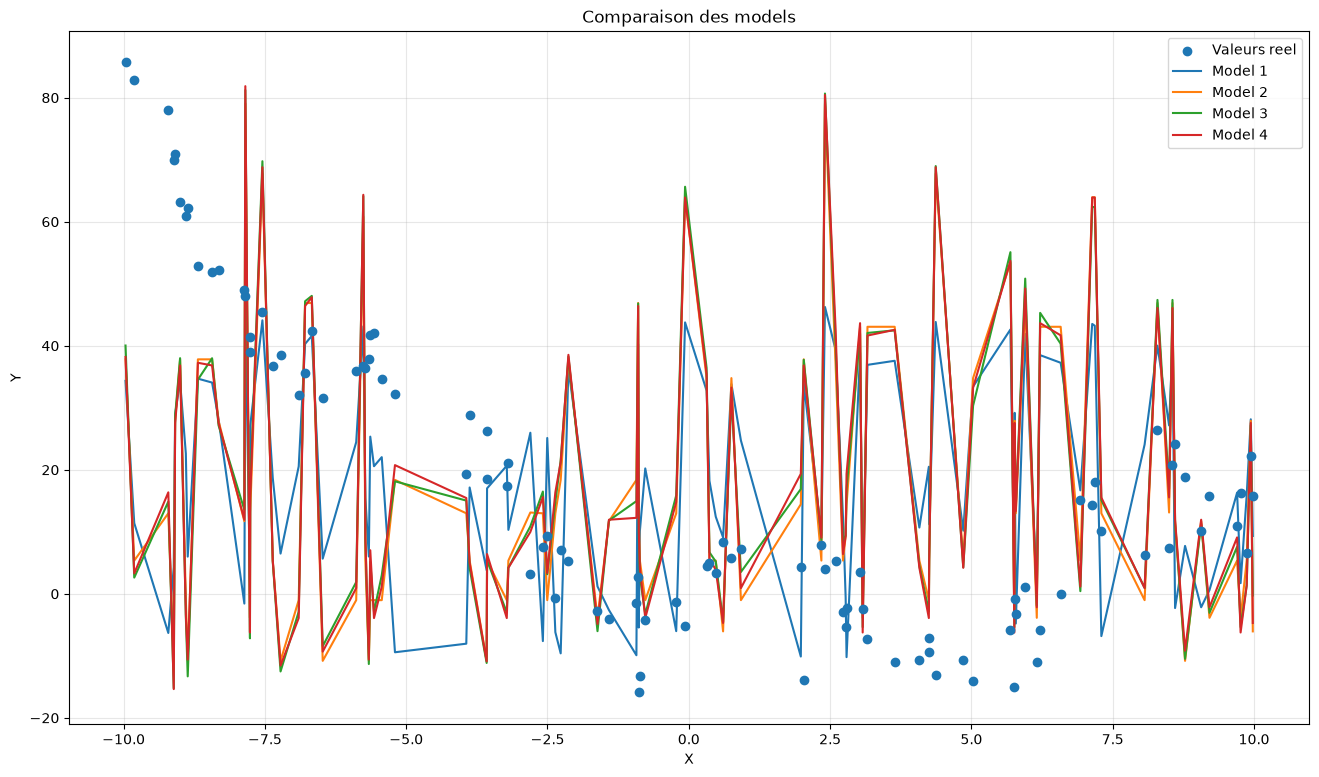

In [65]:
ordre = np.argsort(x_test.values.ravel())

x_test_sort = x_test.values.ravel()[ordre]

y_test_sort = y_test.values.ravel()[ordre]

pred_m1 = pred_m1.ravel()[ordre]

pred_m2 = pred_m2.ravel()[ordre]

pred_m3 = pred_m3.ravel()[ordre]

pred_m4 = pred_m4.ravel()[ordre]

fig , ax = plt.subplots(figsize=(16,9))

ax.set_title("Nuage de point")

ax.scatter(x_test_sort , y_test_sort , label="Valeurs reel", zorder=5)

ax.plot(x_test_sort , pred_m1, label="Model 1")

ax.plot(x_test_sort , pred_m2, label="Model 2")

ax.plot(x_test_sort , pred_m3, label="Model 3")

ax.plot(x_test_sort , pred_m4, label="Model 4")

ax.set_title("Comparaison des models")

ax.set_xlabel("X")

ax.set_ylabel("Y")

ax.grid(alpha=0.3)

ax.legend()